## 3-4 · DuckDB를 이용한 데이터 분석


In [ ]:
! uv run python -c "import duckdb; print(duckdb.sql(\"SELECT count(*) FROM 'events.parquet'\").fetchone()[0])"

1000000


In [2]:
! ls -lh events.parquet orders_step1.parquet customers.csv orders_enriched.parquet


-rw-r--r--@ 1 hyunjunson  staff   7.9K 10월 11 14:08 customers.csv
-rw-r--r--@ 1 hyunjunson  staff   9.8M 10월 18 20:21 events.parquet
-rw-r--r--@ 1 hyunjunson  staff    24K 10월 11 15:29 orders_enriched.parquet
-rw-r--r--@ 1 hyunjunson  staff    21K 10월  9 14:54 orders_step1.parquet


In [3]:
! uv run python -c "import sys, pandas, duckdb, pyarrow; print(pandas.__version__, duckdb.__version__, pyarrow.__version__, sys.prefix)"

3.0.6 1.5.6 25.0.1 /Users/hyunjunson/study/data-eng/week3/.venv


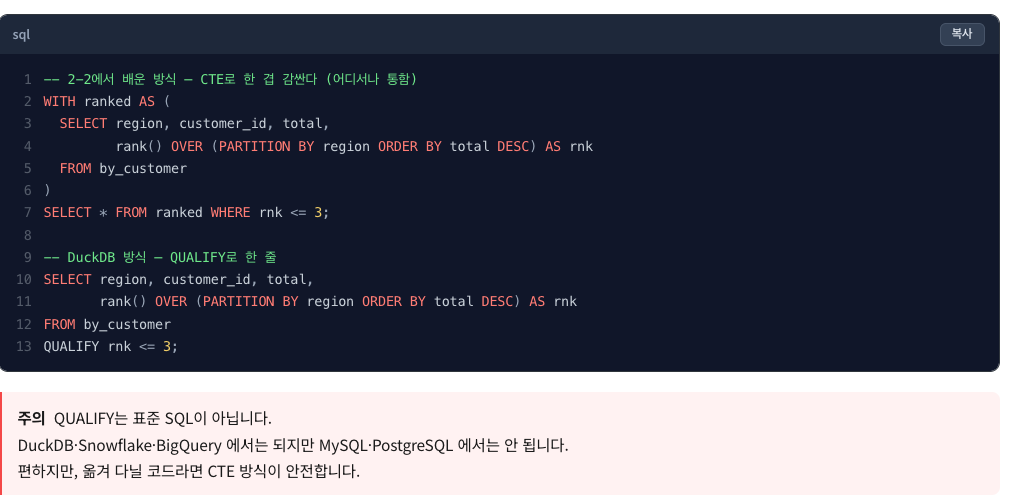

In [6]:
import duckdb
import pandas as pd
 
print(duckdb.sql("""
    SELECT user_id, count(*) AS buys, sum(value) AS spend
    FROM 'events.parquet'
    WHERE event_type = 'buy'
    GROUP BY user_id
    ORDER BY spend DESC
    LIMIT 5
"""))

┌─────────┬───────┬────────┐
│ user_id │ buys  │ spend  │
│  int64  │ int64 │ int128 │
├─────────┼───────┼────────┤
│   12844 │     6 │  44700 │
│   42010 │     6 │  44300 │
│   46170 │     6 │  44100 │
│    4247 │     5 │  44000 │
│   28889 │     5 │  40200 │
└─────────┴───────┴────────┘



In [7]:
sql_result = duckdb.sql("""
    SELECT c.region,
           count(*)                  AS orders,
           sum(o.price * o.quantity) AS total
    FROM 'orders_step1.parquet' AS o
    JOIN 'customers.csv'        AS c
      ON o.customer_id = c.customer_id
    GROUP BY c.region
    ORDER BY total DESC
""").df()
print(sql_result)

  region  orders       total
0     부산     276  77389000.0
1     경기     254  72923000.0
2     서울     235  69007000.0
3     광주     250  68667000.0


In [8]:
pd_result = (pd.read_parquet('orders_enriched.parquet')
             .groupby('region')
             .agg(orders=('order_id', 'count'),
                  total=('amount', 'sum'))
             .reset_index()
             .sort_values('total', ascending=False))
print(pd_result)

  region  orders       total
2     부산     276  77389000.0
0     경기     254  72923000.0
3     서울     235  69007000.0
1     광주     250  68667000.0


In [9]:
merged = sql_result.merge(pd_result, on='region', suffixes=('_sql', '_pd'))
merged['diff'] = merged['total_sql'] - merged['total_pd']
print(merged[['region', 'total_sql', 'total_pd', 'diff']])

  region   total_sql    total_pd  diff
0     부산  77389000.0  77389000.0   0.0
1     경기  72923000.0  72923000.0   0.0
2     서울  69007000.0  69007000.0   0.0
3     광주  68667000.0  68667000.0   0.0


In [10]:
duckdb.sql("""
    WITH daily AS (
        SELECT date_trunc('day', ts) AS d, sum(value) AS revenue
        FROM 'events.parquet'
        WHERE event_type = 'buy'
        GROUP BY d
    )
    SELECT d, revenue,
           sum(revenue) OVER (ORDER BY d) AS cum_revenue
    FROM daily
    ORDER BY d
    LIMIT 5
""")

┌─────────────────────┬─────────┬─────────────┐
│          d          │ revenue │ cum_revenue │
│      timestamp      │ int128  │   int128    │
├─────────────────────┼─────────┼─────────────┤
│ 2026-06-01 00:00:00 │ 4064300 │     4064300 │
│ 2026-06-02 00:00:00 │ 4307800 │     8372100 │
│ 2026-06-03 00:00:00 │ 4148000 │    12520100 │
│ 2026-06-04 00:00:00 │ 4375800 │    16895900 │
│ 2026-06-05 00:00:00 │ 4027700 │    20923600 │
└─────────────────────┴─────────┴─────────────┘

In [11]:
duckdb.sql("""
    SELECT date_trunc('day', ts) AS d, sum(value) AS revenue
    FROM 'events.parquet'
    WHERE event_type = 'buy'
    GROUP BY d
    ORDER BY d
    LIMIT 3
""")

┌─────────────────────┬─────────┐
│          d          │ revenue │
│      timestamp      │ int128  │
├─────────────────────┼─────────┤
│ 2026-06-01 00:00:00 │ 4064300 │
│ 2026-06-02 00:00:00 │ 4307800 │
│ 2026-06-03 00:00:00 │ 4148000 │
└─────────────────────┴─────────┘

In [12]:
try:
    duckdb.sql("""
        SELECT o.customer_id,
               rank() OVER (ORDER BY o.price DESC) AS rnk
        FROM 'orders_step1.parquet' AS o
        WHERE rnk <= 3
    """).fetchall()
except Exception as e:
    print('예상대로 실패:', e)

예상대로 실패: Binder Error: WHERE clause cannot contain window functions!


In [13]:
duckdb.sql("""
    WITH by_customer AS (
        SELECT c.region, o.customer_id,
               sum(o.price * o.quantity) AS total
        FROM 'orders_step1.parquet' AS o
        JOIN 'customers.csv'        AS c
          ON o.customer_id = c.customer_id
        GROUP BY c.region, o.customer_id
    )
    SELECT region, customer_id, total,
           rank() OVER (PARTITION BY region ORDER BY total DESC) AS rnk
    FROM by_customer
    QUALIFY rnk <= 3
    ORDER BY region, rnk
""")

┌─────────┬─────────────┬───────────┬───────┐
│ region  │ customer_id │   total   │  rnk  │
│ varchar │    int64    │  double   │ int64 │
├─────────┼─────────────┼───────────┼───────┤
│ 경기    │         119 │ 3111000.0 │     1 │
│ 경기    │          22 │ 3025000.0 │     2 │
│ 경기    │          24 │ 2839000.0 │     3 │
│ 광주    │          88 │ 3392000.0 │     1 │
│ 광주    │         170 │ 3284000.0 │     2 │
│ 광주    │         157 │ 3031000.0 │     3 │
│ 부산    │          90 │ 3706000.0 │     1 │
│ 부산    │           2 │ 3226000.0 │     2 │
│ 부산    │          46 │ 3025000.0 │     3 │
│ 서울    │          19 │ 4452000.0 │     1 │
│ 서울    │         105 │ 3231000.0 │     2 │
│ 서울    │         194 │ 3132000.0 │     3 │
└─────────┴─────────────┴───────────┴───────┘
  12 rows                         4 columns

In [15]:
duckdb.sql("""
    WITH by_customer AS (
        SELECT c.region, o.customer_id, sum(o.price * o.quantity) AS total
        FROM 'orders_step1.parquet' AS o
        JOIN 'customers.csv' AS c ON o.customer_id = c.customer_id
        GROUP BY c.region, o.customer_id
    ),
    ranked AS (
        SELECT *, rank() OVER (PARTITION BY region ORDER BY total DESC) AS rnk
        FROM by_customer
    )
    SELECT * FROM ranked WHERE rnk <= 3 ORDER BY region, rnk
""")

┌─────────┬─────────────┬───────────┬───────┐
│ region  │ customer_id │   total   │  rnk  │
│ varchar │    int64    │  double   │ int64 │
├─────────┼─────────────┼───────────┼───────┤
│ 경기    │         119 │ 3111000.0 │     1 │
│ 경기    │          22 │ 3025000.0 │     2 │
│ 경기    │          24 │ 2839000.0 │     3 │
│ 광주    │          88 │ 3392000.0 │     1 │
│ 광주    │         170 │ 3284000.0 │     2 │
│ 광주    │         157 │ 3031000.0 │     3 │
│ 부산    │          90 │ 3706000.0 │     1 │
│ 부산    │           2 │ 3226000.0 │     2 │
│ 부산    │          46 │ 3025000.0 │     3 │
│ 서울    │          19 │ 4452000.0 │     1 │
│ 서울    │         105 │ 3231000.0 │     2 │
│ 서울    │         194 │ 3132000.0 │     3 │
└─────────┴─────────────┴───────────┴───────┘
  12 rows                         4 columns

In [16]:
duckdb.sql("""
    WITH daily AS (
        SELECT date_trunc('day', ts) AS d, sum(value) AS revenue
        FROM 'events.parquet'
        WHERE event_type = 'buy'
        GROUP BY d
    )
    SELECT d, revenue,
           round(avg(revenue) OVER (
               ORDER BY d ROWS BETWEEN 6 PRECEDING AND CURRENT ROW
           )) AS ma7
    FROM daily
    ORDER BY d
    LIMIT 10
""")

┌─────────────────────┬─────────┬───────────┐
│          d          │ revenue │    ma7    │
│      timestamp      │ int128  │  double   │
├─────────────────────┼─────────┼───────────┤
│ 2026-06-01 00:00:00 │ 4064300 │ 4064300.0 │
│ 2026-06-02 00:00:00 │ 4307800 │ 4186050.0 │
│ 2026-06-03 00:00:00 │ 4148000 │ 4173367.0 │
│ 2026-06-04 00:00:00 │ 4375800 │ 4223975.0 │
│ 2026-06-05 00:00:00 │ 4027700 │ 4184720.0 │
│ 2026-06-06 00:00:00 │ 4056700 │ 4163383.0 │
│ 2026-06-07 00:00:00 │ 4172100 │ 4164629.0 │
│ 2026-06-08 00:00:00 │ 4133000 │ 4174443.0 │
│ 2026-06-09 00:00:00 │ 4112500 │ 4146543.0 │
│ 2026-06-10 00:00:00 │ 4160100 │ 4148271.0 │
└─────────────────────┴─────────┴───────────┘
  10 rows                         3 columns

In [17]:
duckdb.sql("""
    SELECT event_type, date_trunc('day', ts) AS d, count(*) AS cnt
    FROM 'events.parquet'
    GROUP BY ALL
    ORDER BY d, event_type
    LIMIT 5
""")

┌────────────┬─────────────────────┬───────┐
│ event_type │          d          │  cnt  │
│  varchar   │      timestamp      │ int64 │
├────────────┼─────────────────────┼───────┤
│ buy        │ 2026-06-01 00:00:00 │   818 │
│ cart       │ 2026-06-01 00:00:00 │  2540 │
│ view       │ 2026-06-01 00:00:00 │ 13389 │
│ buy        │ 2026-06-02 00:00:00 │   842 │
│ cart       │ 2026-06-02 00:00:00 │  2499 │
└────────────┴─────────────────────┴───────┘

In [18]:
duckdb.sql("SELECT * EXCLUDE (event_id) FROM 'events.parquet' LIMIT 3")

┌─────────┬────────────┬───────┬─────────────────────┐
│ user_id │ event_type │ value │         ts          │
│  int64  │  varchar   │ int64 │      timestamp      │
├─────────┼────────────┼───────┼─────────────────────┤
│    4463 │ view       │  5700 │ 2026-07-16 03:28:19 │
│   38698 │ view       │  8400 │ 2026-06-10 23:02:55 │
│   32729 │ view       │  9500 │ 2026-06-10 08:17:19 │
└─────────┴────────────┴───────┴─────────────────────┘

In [19]:
duckdb.sql("SELECT max(COLUMNS('^value$')) FROM 'events.parquet'")

┌───────┐
│ value │
│ int64 │
├───────┤
│  9900 │
└───────┘

In [20]:
# roundtrip.py — 1~4단계를 이 파일에 이어 붙입니다
import duckdb
import pandas as pd

top = duckdb.sql("""
    SELECT user_id, sum(value) AS spend
    FROM 'events.parquet'
    WHERE event_type = 'buy'
    GROUP BY user_id
    ORDER BY spend DESC
    LIMIT 100
""").df()

print(type(top), top.shape)
print('spend 범위:', top['spend'].min(), '~', top['spend'].max())


<class 'pandas.DataFrame'> (100, 2)
spend 범위: 28700.0 ~ 44700.0


In [21]:
# 일부러 실패 — 경계를 눈대중으로 정하면?
top['grade'] = pd.cut(top['spend'],
                      bins=[0, 15000, 25000, float('inf')],
                      labels=['B', 'A', 'S'])
print(top['grade'].value_counts())

grade
S    100
B      0
A      0
Name: count, dtype: int64


In [22]:
q = top['spend'].quantile([0.33, 0.66]).tolist()
print('경계값 후보:', [round(x) for x in q])
 
top['grade2'] = pd.cut(top['spend'],
                       bins=[0, q[0], q[1], float('inf')],
                       labels=['B', 'A', 'S'])
print(top['grade2'].value_counts())

경계값 후보: [30200, 32800]
grade2
B    34
A    34
S    32
Name: count, dtype: int64


In [23]:
grade_summary = duckdb.sql("""
    SELECT grade2 AS grade, count(*) AS users, avg(spend) AS avg_spend
    FROM top
    GROUP BY grade2
    ORDER BY avg_spend DESC
""").df()
print(grade_summary)

  grade  users     avg_spend
0     S     32  36343.750000
1     A     34  31658.823529
2     B     34  29476.470588


In [24]:
# 3단계 — roundtrip.py 끝에 이어 붙입니다
# ① SQL — 100만 행에서 사용자별 요약으로 줄인다
users = duckdb.sql("""
    SELECT user_id,
           count(*) FILTER (WHERE event_type = 'view') AS views,
           count(*) FILTER (WHERE event_type = 'cart') AS carts,
           count(*) FILTER (WHERE event_type = 'buy')  AS buys,
           sum(value) FILTER (WHERE event_type = 'buy') AS spend
    FROM 'events.parquet'
    GROUP BY user_id
""").df()
print('① SQL 집계 후:', users.shape)

# ② Pandas — 전환율 계산과 라벨링 (세밀한 규칙)
users['cvr'] = (users['buys'] / users['views']).fillna(0).round(3)
users['segment'] = 'normal'
users.loc[users['cvr'] >= 0.1, 'segment'] = 'high_intent'
users.loc[users['buys'] == 0, 'segment'] = 'browser'
print('② Pandas 가공 후:', users.shape)

# ③ SQL — 세그먼트별 요약
seg = duckdb.sql("""
    SELECT segment,
           count(*) AS users,
           round(avg(cvr), 3) AS avg_cvr,
           round(avg(coalesce(spend, 0))) AS avg_spend
    FROM users
    GROUP BY segment
    ORDER BY users DESC
""").df()
print('③ 세그먼트 요약')
print(seg)

① SQL 집계 후: (50000, 5)
② Pandas 가공 후: (50000, 7)
③ 세그먼트 요약
       segment  users  avg_cvr  avg_spend
0      browser  18499    0.000        0.0
1       normal  18015    0.065     5325.0
2  high_intent  13486    0.162    11418.0


In [25]:
# 4단계 — roundtrip.py 끝에 이어 붙입니다
import os
 
# Pandas로 저장
users.to_parquet('user_segments.parquet', index=False)
 
# DuckDB로 저장 (DataFrame을 그대로 COPY)
duckdb.sql("COPY (SELECT * FROM seg) TO 'segment_summary.parquet' (FORMAT parquet)")
 
for f in ['user_segments.parquet', 'segment_summary.parquet']:
    print(f, f'{os.path.getsize(f)/1024:.1f} KB')

user_segments.parquet 485.4 KB
segment_summary.parquet 0.6 KB


In [26]:
# df_cost.py — 5단계 단독 파일(100만 행을 통째로 올리니 roundtrip.py 에 붙이지 않습니다)
import time
import duckdb
 
# 나쁜 예 — 100만 행을 통째로 DataFrame으로
t0 = time.perf_counter()
big = duckdb.sql("SELECT * FROM 'events.parquet'").df()
t1 = time.perf_counter()
print(f'전체 변환  : {t1-t0:.2f}초, {big.memory_usage(deep=True).sum()/1024/1024:,.0f} MB, {len(big):,}행')
 
# 좋은 예 — 줄인 다음에
t0 = time.perf_counter()
small = duckdb.sql("SELECT event_type, sum(value) AS v FROM 'events.parquet' GROUP BY event_type").df()
t1 = time.perf_counter()
print(f'집계 후 변환: {t1-t0:.2f}초, {small.memory_usage(deep=True).sum():,} bytes, {len(small)}행')
 
del big


전체 변환  : 0.15초, 42 MB, 1,000,000행
집계 후 변환: 0.00초, 191 bytes, 3행


In [27]:
import duckdb
 
print(duckdb.sql("""
    WITH per_user AS (
        SELECT user_id,
               max(CASE WHEN event_type = 'view' THEN 1 ELSE 0 END) AS viewed,
               max(CASE WHEN event_type = 'cart' THEN 1 ELSE 0 END) AS carted,
               max(CASE WHEN event_type = 'buy'  THEN 1 ELSE 0 END) AS bought
        FROM 'events.parquet'
        GROUP BY user_id
    )
    SELECT sum(viewed) AS viewed,
           sum(carted) AS carted,
           sum(bought) AS bought,
           round(sum(carted) * 100.0 / sum(viewed), 1) AS view_to_cart,
           round(sum(bought) * 100.0 / sum(carted), 1) AS cart_to_buy
    FROM per_user
"""))

┌────────┬────────┬────────┬──────────────┬─────────────┐
│ viewed │ carted │ bought │ view_to_cart │ cart_to_buy │
│ int128 │ int128 │ int128 │    double    │   double    │
├────────┼────────┼────────┼──────────────┼─────────────┤
│  50000 │  47525 │  31501 │         95.1 │        66.3 │
└────────┴────────┴────────┴──────────────┴─────────────┘

